# Online Retail II: Load the Data

We’ll start by loading the Excel workbook and taking a look at the data. We can work through the segmentation together, one step at a time.

In [72]:
from pathlib import Path

import pandas as pd

project_dir = Path.cwd()
if not (project_dir / "Data").is_dir():
    project_dir = project_dir / "learning-python"
excel_file = project_dir / "Data" / "online_retail_II.xlsx"
if not excel_file.exists():
    raise FileNotFoundError(f"Workbook not found: {excel_file}")

# Read both workbook sheets, then combine their rows into one DataFrame.
sheets = pd.read_excel(excel_file, sheet_name=None)
data = pd.concat(sheets.values(), ignore_index=True)
data = data.dropna(subset=["Customer ID"]).copy()
data["IsReturnTransaction"] = data["Invoice"].astype(str).str.contains("C", case=False, na=False)

print("Sheets loaded:", list(sheets))
print("Combined data shape:", data.shape)
display(data.head())


Sheets loaded: ['Year 2009-2010', 'Year 2010-2011']
Combined data shape: (824364, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsReturnTransaction
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False


In [54]:
data.head(), data.shape

(  Invoice StockCode                          Description  Quantity  \
 0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
 1  489434    79323P                   PINK CHERRY LIGHTS        12   
 2  489434    79323W                  WHITE CHERRY LIGHTS        12   
 3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
 4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   
 
           InvoiceDate  Price  Customer ID         Country  
 0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
 1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
 2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
 3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
 4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  ,
 (824364, 8))

In [55]:
# Count distinct customers and countries (missing values are excluded).
unique_customer_count = data["Customer ID"].nunique()
unique_country_count = data["Country"].nunique()

print(f"Unique customers: {unique_customer_count:,}")
print(f"Unique countries: {unique_country_count:,}")

# Keep all distinct pairs in case a StockCode has multiple descriptions.
stock_description_mapping = (
    data[["StockCode", "Description"]]
    .dropna(subset=["StockCode", "Description"])
    .drop_duplicates()
    .sort_values(["StockCode", "Description"])
    .reset_index(drop=True)
)
print(f"Distinct StockCode/Description pairs: {len(stock_description_mapping):,}")
display(stock_description_mapping.head(20))

# Derive calendar and 24-hour clock fields from InvoiceDate.
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"], errors="coerce")
data["Year"] = data["InvoiceDate"].dt.year
data["Month"] = data["InvoiceDate"].dt.month
data["Day"] = data["InvoiceDate"].dt.day
data["Weekday"] = data["InvoiceDate"].dt.day_name()
data["Time"] = data["InvoiceDate"].dt.hour

display(data[["InvoiceDate", "Year", "Month", "Day", "Weekday", "Time"]].head())

Unique customers: 5,942
Unique countries: 41
Distinct StockCode/Description pairs: 5,331


,StockCode,Description
0,10002,INFLATABLE POLITICAL GLOBE
1,10080,GROOVY CACTUS INFLATABLE
2,10109,BENDY COLOUR PENCILS
3,10120,DOGGY RUBBER
4,10125,MINI FUNKY DESIGN TAPES
5,10133,COLOURING PENCILS BROWN TUBE
6,10134,COLOURING PENCILS BROWN TUBE
7,10135,COLOURING PENCILS BROWN TUBE
8,10138,ASSORTED COLOUR JUMBO PEN
9,11001,ASSTD DESIGN RACING CAR PEN


,InvoiceDate,Year,Month,Day,Weekday,Time
0,2009-12-01 07:45:00,2009,12,1,Tuesday,7
1,2009-12-01 07:45:00,2009,12,1,Tuesday,7
2,2009-12-01 07:45:00,2009,12,1,Tuesday,7
3,2009-12-01 07:45:00,2009,12,1,Tuesday,7
4,2009-12-01 07:45:00,2009,12,1,Tuesday,7


In [56]:
data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year,Month,Day,Weekday,Time
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1,Tuesday,7
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,Tuesday,7
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,Tuesday,7
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009,12,1,Tuesday,7
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1,Tuesday,7


In [57]:
data.groupby("Time").size()


Time
6         41
7       1123
8      15630
9      42545
10     76008
11    102615
12    147020
13    133962
14    112356
15     91081
16     54719
17     28355
18      7980
19      8777
20      2151
21         1
dtype: int64

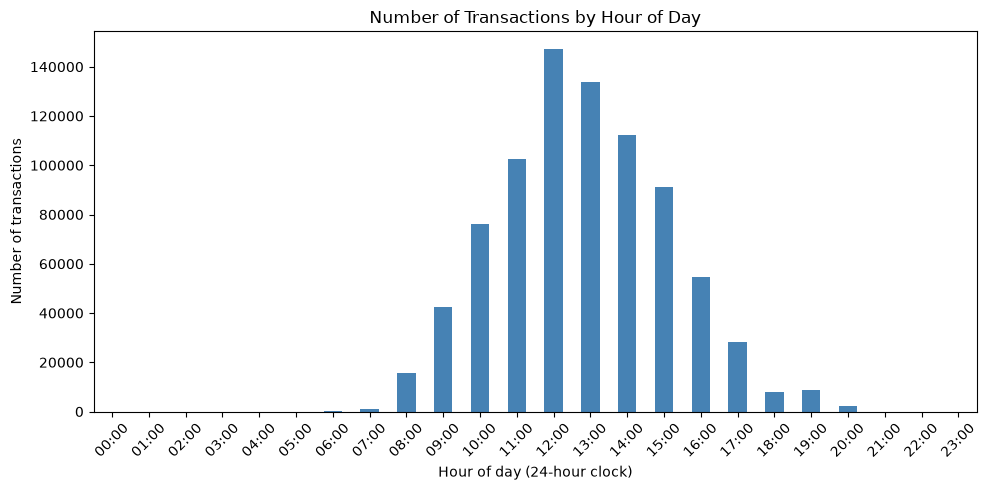

In [58]:
import matplotlib.pyplot as plt

# Count transaction rows for each hour, including hours with no transactions.
transactions_by_hour = data["Time"].value_counts().reindex(range(24), fill_value=0).sort_index()

ax = transactions_by_hour.plot(kind="bar", figsize=(10, 5), color="steelblue")
ax.set_title("Number of Transactions by Hour of Day")
ax.set_xlabel("Hour of day (24-hour clock)")
ax.set_ylabel("Number of transactions")
ax.set_xticks(range(24), [f"{hour:02d}:00" for hour in range(24)], rotation=45)
plt.tight_layout()
plt.show()

In [59]:
# Rank StockCodes by transaction-line count, then calculate each code's share
# and the running cumulative share of all transaction lines.
stockcode_transaction_share = (
    data.groupby("StockCode")
    .size()
    .reset_index(name="TransactionCount")
    .sort_values("TransactionCount", ascending=False)
    .reset_index(drop=True)
)
stockcode_transaction_share["Percentage"] = (
    stockcode_transaction_share["TransactionCount"]
    / stockcode_transaction_share["TransactionCount"].sum()
    * 100
)
stockcode_transaction_share["CumulativePercentage"] = (
    stockcode_transaction_share["TransactionCount"].cumsum()
    / stockcode_transaction_share["TransactionCount"].sum()
    * 100
)

display(stockcode_transaction_share.round(2).head(20))

,StockCode,TransactionCount,Percentage,CumulativePercentage
0,85123A,5322,0.65,0.65
1,22423,3777,0.46,1.10
2,85099B,3446,0.42,1.52
3,84879,2794,0.34,1.86
4,20725,2755,0.33,2.19
5,21212,2679,0.32,2.52
6,21232,2190,0.27,2.79
7,20727,2161,0.26,3.05
8,21034,2150,0.26,3.31
9,47566,2144,0.26,3.57


In [60]:
# Flag each transaction by time of day using the agreed hour ranges.
time_window_labels = ["Night Owl", "Early Morning", "Office Hours", "Evening"]
data["TimeWindow"] = pd.cut(
    data["Time"],
    bins=[-1, 6, 10, 17, 23],
    labels=time_window_labels,
)

transactions_by_time_window = (
    data["TimeWindow"]
    .value_counts(sort=False)
    .rename("TransactionCount")
    .to_frame()
)
transactions_by_time_window["Percentage"] = (
    transactions_by_time_window["TransactionCount"] / len(data) * 100
)
display(transactions_by_time_window.round(2))

,TransactionCount,Percentage
TimeWindow,,
Night Owl,41,0.00
Early Morning,135306,16.41
Office Hours,670108,81.29
Evening,18909,2.29


In [61]:
data.head()


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year,Month,Day,Weekday,Time,TimeWindow
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1,Tuesday,7,Early Morning
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,Tuesday,7,Early Morning
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,Tuesday,7,Early Morning
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009,12,1,Tuesday,7,Early Morning
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1,Tuesday,7,Early Morning


In [62]:
# Measure every transaction's age relative to the latest transaction in this dataset.
reference_date = data["InvoiceDate"].max()
data["TransactionAgeDays"] = (reference_date - data["InvoiceDate"]).dt.days

age_labels = [
    "Last week (0-7 days)",
    "Last month (8-30 days)",
    "Last quarter (31-90 days)",
    "Last semester (91-180 days)",
    "Last year (181-365 days)",
    "Older than 1 year",
]
data["TransactionAgeGroup"] = pd.cut(
    data["TransactionAgeDays"],
    bins=[-1, 7, 30, 90, 180, 365, float("inf")],
    labels=age_labels,
)

print(f"Reference date (latest transaction): {reference_date}")
display(data[["InvoiceDate", "TransactionAgeDays", "TransactionAgeGroup"]].head())

Reference date (latest transaction): 2011-12-09 12:50:00


,InvoiceDate,TransactionAgeDays,TransactionAgeGroup
0,2009-12-01 07:45:00,738,Older than 1 year
1,2009-12-01 07:45:00,738,Older than 1 year
2,2009-12-01 07:45:00,738,Older than 1 year
3,2009-12-01 07:45:00,738,Older than 1 year
4,2009-12-01 07:45:00,738,Older than 1 year


In [63]:
data.shape

(824364, 16)

In [64]:
data.isnull().sum()/data.shape[0]

Invoice                0.0
StockCode              0.0
Description            0.0
Quantity               0.0
InvoiceDate            0.0
Price                  0.0
Customer ID            0.0
Country                0.0
Year                   0.0
Month                  0.0
Day                    0.0
Weekday                0.0
Time                   0.0
TimeWindow             0.0
TransactionAgeDays     0.0
TransactionAgeGroup    0.0
dtype: float64

In [73]:
# Step 1: one row per customer with distinct invoice count and total sales.
# Sales are calculated per line as Quantity * Price; returns reduce net sales.
customer_transactions = data.dropna(subset=["Invoice"]).copy()
customer_transactions["SalesAmount"] = (
    customer_transactions["Quantity"] * customer_transactions["Price"]
)

customer_summary = (
    customer_transactions.groupby("Customer ID")
    .agg(
        TransactionCount=("Invoice", "nunique"),
        TotalItemCount=("Quantity", "sum"),
        TotalNetSales=("SalesAmount", "sum"),
    )
    .reset_index()
)
return_invoice_counts = (
    customer_transactions.loc[customer_transactions["IsReturnTransaction"]]
    .groupby("Customer ID")["Invoice"]
    .nunique()
)
customer_summary["ReturnInvoiceCount"] = (
    customer_summary["Customer ID"].map(return_invoice_counts).fillna(0).astype(int)
)

print(f"Customer-level dataset shape: {customer_summary.shape}")
display(customer_summary.head())

Customer-level dataset shape: (5942, 5)


,Customer ID,TransactionCount,TotalItemCount,TotalNetSales,ReturnInvoiceCount
0,12346.0,17,52,-64.68,5
1,12347.0,8,3286,5633.32,0
2,12348.0,5,2714,2019.40,0
3,12349.0,5,1619,4404.54,1
4,12350.0,1,197,334.40,0


In [86]:
# A customer/StockCode pair is a final sell when its latest transaction is not a return.
purchase_return_rows = data.dropna(
    subset=["Customer ID", "StockCode", "InvoiceDate", "Quantity", "Price"]
).copy()
latest_pair_status = (
    purchase_return_rows.sort_values("InvoiceDate", kind="stable")
    .groupby(["Customer ID", "StockCode"], sort=False)
    .tail(1)[["Customer ID", "StockCode", "IsReturnTransaction"]]
    .rename(columns={"IsReturnTransaction": "LatestTransactionIsReturn"})
)
purchase_return_rows = purchase_return_rows.merge(
    latest_pair_status,
    on=["Customer ID", "StockCode"],
    how="left",
    validate="many_to_one",
)
purchase_return_rows["IsFinalSell"] = ~purchase_return_rows["LatestTransactionIsReturn"]
final_sell_rows = purchase_return_rows.loc[purchase_return_rows["IsFinalSell"]].copy()
final_sell_rows["NetSales"] = final_sell_rows["Quantity"] * final_sell_rows["Price"]
final_sell_rows["PurchaseMonth"] = final_sell_rows["InvoiceDate"].dt.to_period("M")

# Returns within a pair that ends in a sale remain included as negative quantities/sales.
eligible_totals = final_sell_rows.groupby("Customer ID").agg(
    EligibleQuantity=("Quantity", "sum"),
    EligibleSales=("NetSales", "sum"),
)
active_purchase_months = (
    final_sell_rows.loc[~final_sell_rows["IsReturnTransaction"]]
    .groupby("Customer ID")["PurchaseMonth"]
    .nunique()
)
customer_monthly_averages = eligible_totals.join(
    active_purchase_months.rename("ActivePurchaseMonths")
)
customer_monthly_averages["AverageMonthlyQuantityNotReturned"] = (
    customer_monthly_averages["EligibleQuantity"]
    / customer_monthly_averages["ActivePurchaseMonths"]
)
customer_monthly_averages["AverageMonthlySalesNotReturned"] = (
    customer_monthly_averages["EligibleSales"]
    / customer_monthly_averages["ActivePurchaseMonths"]
)

average_columns = [
    "ActivePurchaseMonths",
    "AverageMonthlyQuantityNotReturned",
    "AverageMonthlySalesNotReturned",
]
customer_summary = customer_summary.drop(columns=average_columns, errors="ignore").merge(
    customer_monthly_averages[average_columns].reset_index(),
    on="Customer ID",
    how="left",
)
customer_summary[average_columns] = customer_summary[average_columns].fillna(0)

print(f"Customer/StockCode pairs classified as final sell: {latest_pair_status['LatestTransactionIsReturn'].eq(False).sum():,}")
display(customer_summary[["Customer ID", *average_columns]].head())

Customer/StockCode pairs classified as final sell: 472,590


,Customer ID,ActivePurchaseMonths,AverageMonthlyQuantityNotReturned,AverageMonthlySalesNotReturned
0,12346.0,3.0,8.333333,56.786667
1,12347.0,8.0,410.750000,704.165000
2,12348.0,5.0,542.800000,403.880000
3,12349.0,4.0,405.000000,1104.872500
4,12350.0,1.0,197.000000,334.400000


In [69]:
data[data['Quantity'] < 0].head(10)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year,Month,Day,Weekday,Time,TimeWindow,TransactionAgeDays,TransactionAgeGroup
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,2009,12,1,Tuesday,10,Early Morning,738,Older than 1 year
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,2009,12,1,Tuesday,10,Early Morning,738,Older than 1 year
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,2009,12,1,Tuesday,10,Early Morning,738,Older than 1 year
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,2009,12,1,Tuesday,10,Early Morning,738,Older than 1 year
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,2009,12,1,Tuesday,10,Early Morning,738,Older than 1 year
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,2009,12,1,Tuesday,10,Early Morning,738,Older than 1 year
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,2009,12,1,Tuesday,10,Early Morning,738,Older than 1 year
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia,2009,12,1,Tuesday,10,Early Morning,738,Older than 1 year
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,2009,12,1,Tuesday,10,Early Morning,738,Older than 1 year
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom,2009,12,1,Tuesday,10,Early Morning,738,Older than 1 year


In [84]:
data[data['Customer ID']==17345.0].sort_values(by='Description', ascending=False).head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsReturnTransaction
497590,535946,84836,ZINC METAL HEART DECORATION,4,2010-11-29 11:54:00,1.25,17345.0,United Kingdom,False
1024396,578548,84836,ZINC METAL HEART DECORATION,5,2011-11-24 15:02:00,1.25,17345.0,United Kingdom,False
497574,535946,85032D,YULETIDE IMAGES GIFT WRAP SET,4,2010-11-29 11:54:00,2.10,17345.0,United Kingdom,False
185212,507020,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,48,2010-05-05 14:34:00,0.21,17345.0,United Kingdom,False
2892,C489636,21578,WOODLAND DESIGN COTTON TOTE BAG,-2,2009-12-01 15:34:00,2.25,17345.0,United Kingdom,True
2897,C489636,21330,WOODLAND ANIMAL WRITING SET,-9,2009-12-01 15:34:00,1.65,17345.0,United Kingdom,True
1024429,578548,22696,WICKER WREATH LARGE,4,2011-11-24 15:02:00,1.95,17345.0,United Kingdom,False
1024387,578548,23323,WHITE WICKER STAR,7,2011-11-24 15:02:00,2.10,17345.0,United Kingdom,False
1024391,578548,23210,WHITE ROCKING HORSE HAND PAINTED,3,2011-11-24 15:02:00,1.25,17345.0,United Kingdom,False
855294,565856,71053,WHITE METAL LANTERN,4,2011-09-07 14:09:00,3.75,17345.0,United Kingdom,False


In [85]:
data[data['Quantity'] < 0].head(1000)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsReturnTransaction
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,True
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,True
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,True
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,True
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,True
...,...,...,...,...,...,...,...,...,...
44707,C493329,22333,RETRO SPORT PARTY BAG + STICKER SET,-1,2009-12-23 09:54:00,1.65,12472.0,Germany,True
44708,C493332,20952,PORCELAIN CHERUB BELL SMALL,-12,2009-12-23 10:00:00,1.25,13883.0,United Kingdom,True
44717,C493362,85099C,JUMBO BAG BAROQUE BLACK WHITE,-2,2009-12-23 10:17:00,1.65,14477.0,United Kingdom,True
44782,C493373,D,Discount,-1,2009-12-23 11:22:00,64.37,15044.0,United Kingdom,True


,Price
count,824364.00
mean,3.68
std,70.24
min,0.00
25%,1.25
50%,1.95
75%,3.75
max,38970.00


99th-percentile price cap: 14.95


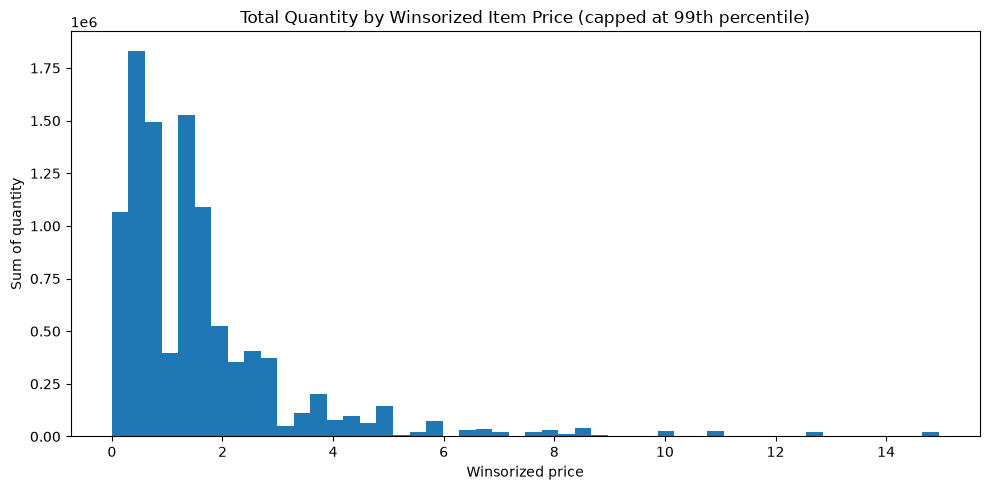

In [66]:
# Summarize line-item prices and plot their distribution.
price_values = data["Price"].dropna()
display(price_values.describe().to_frame(name="Price").round(2))

price_quantity = data.loc[data["Price"] > 0, ["Price", "Quantity"]].dropna().copy()
price_99th_percentile = price_quantity["Price"].quantile(0.99)
price_quantity["PriceWinsorized"] = price_quantity["Price"].clip(upper=price_99th_percentile)
print(f"99th-percentile price cap: {price_99th_percentile:.2f}")
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(
    price_quantity["PriceWinsorized"],
    bins=50,
    weights=price_quantity["Quantity"],
)
ax.set_title("Total Quantity by Winsorized Item Price (capped at 99th percentile)")
ax.set_xlabel("Winsorized price")
ax.set_ylabel("Sum of quantity")
plt.tight_layout()
plt.show()

In [67]:
data.describe()


,Quantity,InvoiceDate,Price,Customer ID,Year,Month,Day,Time,TransactionAgeDays
count,824364.000000,824364,824364.000000,824364.000000,824364.000000,824364.000000,824364.000000,824364.000000,824364.000000
mean,12.414574,2011-01-01 22:29:28.042055,3.676800,15324.638504,2010.422410,7.501498,15.201500,12.810876,341.060728
min,-80995.000000,2009-12-01 07:45:00,0.000000,12346.000000,2009.000000,1.000000,1.000000,6.000000,0.000000
25%,2.000000,2010-07-06 11:58:00,1.250000,13975.000000,2010.000000,5.000000,8.000000,11.000000,134.000000
50%,5.000000,2010-12-03 14:26:00,1.950000,15255.000000,2010.000000,8.000000,15.000000,13.000000,370.000000
75%,12.000000,2011-07-27 15:14:00,3.750000,16797.000000,2011.000000,11.000000,23.000000,14.000000,521.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,2011.000000,12.000000,31.000000,21.000000,738.000000
std,188.976099,NaN,70.241388,1697.464450,0.566598,3.448798,8.694601,2.302335,218.845611
